# Práctica: Exploración y preprocesamiento de datos

**Autor:** Julio Úbeda Quesada · Versión en Python del ejercicio original en R

Este notebook replica, en Python, la actividad de exploración y preprocesamiento
sobre un conjunto de datos de **salud del sueño y estilo de vida**. El dataset
contiene variables relacionadas con hábitos de sueño, actividad física, niveles
de estrés y otros factores de salud.

El flujo de trabajo cubre: carga y preparación de los datos, normalización de
variables categóricas, corrección de inconsistencias en variables cuantitativas,
detección y tratamiento de valores erróneos o atípicos, imputación mediante
k-vecinos más cercanos (KNN), cálculo e interpretación de correlaciones, y un
análisis descriptivo y visual final. El resultado es un archivo de datos
procesado, listo para análisis posteriores.

In [1]:
import sys
sys.path.append("../../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from scipy.stats import pearsonr

from stats_toolkit import descriptive as desc

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Preparación del conjunto de datos

### 1.1. Cargar el archivo de datos

Cargamos el archivo Excel con los datos de salud del sueño y estilo de vida.

In [2]:
df = pd.read_excel("data/sleephealth.xlsx")

print(f"El dataset tiene {df.shape[0]} filas y {df.shape[1]} columnas.\n")
desc.describe_df(df)

El dataset tiene 374 filas y 13 columnas.



,Column,Data Type,Non-null Count,% Null Values,Unique Values,TopCounts,mean,median,std,min,25%,75%,max
0,Person.ID,int64,374,0.00,372,None,187.500000,187.5,108.108717,1.0,94.25,280.75,374.0
1,Gender,str,374,0.00,2,"Male (189), Female (185)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Age,float64,371,0.80,34,None,57.840970,43.0,121.153550,27.0,36.00,50.00,999.0
3,Occupation,str,374,0.00,12,"Nurse (73), Doctor (71), Engineer (60)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Sleep.Duration,str,374,0.00,29,"7.2 (36), 6 (31), 7.8 (27)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Quality.of.Sleep,int64,374,0.00,6,None,7.312834,7.0,1.196956,4.0,6.00,8.00,9.0
6,Physical.Activity.Level,int64,374,0.00,16,None,59.171123,60.0,20.830804,30.0,45.00,75.00,90.0
7,Stress.Level,int64,374,0.00,6,None,5.385027,5.0,1.774526,3.0,4.00,7.00,8.0
8,BMI.Category,str,374,0.00,4,"Normal (195), Overweight (148), Normal Weight ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Blood.Pressure,str,374,0.00,25,"130/85 (99), 125/80 (65), 140/95 (65)",NaN,NaN,NaN,NaN,NaN,NaN,NaN


Tras cargar los datos, el `DataFrame` tiene 374 filas y 13 columnas, coincidiendo
con el archivo original.

### 1.2. Identificación de valores duplicados

El conjunto de datos debería tener un registro por `Person.ID`; cualquier `ID`
repetido indica un error de captura. Filtramos los `ID` que aparecen más de
una vez:

In [3]:
duplicates_by_id = desc.detect_duplicates(df, subset=["Person.ID"])
duplicates_by_id

Se encontraron 3 filas duplicadas según: ['Person.ID'].


,Person.ID,Gender,Age,Occupation,Sleep.Duration,Quality.of.Sleep,Physical.Activity.Level,Stress.Level,BMI.Category,Blood.Pressure,Heart.Rate,Daily.Steps,Sleep.Disorder
33,35,Male,31.0,Doctor,6.1,6,30,8,Normal,125/80,72,5000,NaN
34,35,Male,31.0,Doctor,7.7,7,75,6,Normal,120/80,70,8000,NaN
35,35,Male,31.0,Doctor,6.1,6,30,8,Normal,125/80,72,5000,NaN


La presencia de registros con el mismo `Person.ID` indica duplicados, posiblemente
por errores en la captura o consolidación de los datos. En lugar de eliminar
información, creamos una columna `ID` nueva, secuencial y única, y la usamos
como identificador definitivo a partir de ahora.

In [4]:
df = df.reset_index(drop=True)
df["ID"] = df.index + 1

# Comprobamos que ahora es único por registro
assert df["ID"].is_unique
print("El nuevo identificador 'ID' es único para las", len(df), "filas.")

El nuevo identificador 'ID' es único para las 374 filas.


### 1.3. Identificación de valores vacíos y/o nulos

Revisamos si hay valores nulos (`NaN`), espacios en blanco o cadenas vacías en
cualquier columna.

In [5]:
resumen_cols = desc.describe_df(df)
columnas_con_vacios = resumen_cols.loc[resumen_cols["% Null Values"] > 0, "Column"].tolist()

print("Columnas con valores vacíos o nulos:", columnas_con_vacios)
df[columnas_con_vacios].isna().sum()

Columnas con valores vacíos o nulos: ['Age', 'Sleep.Disorder']


Age                 3
Sleep.Disorder    219
dtype: int64

`Age` tiene valores nulos genuinos, y `Sleep.Disorder` tiene muchos `NaN` — pero
en este caso no son datos perdidos: representan ausencia de trastorno del sueño.
Más adelante lo recodificamos explícitamente como la categoría `"None"`.

### 1.4. Simplificación del nombre de las columnas

Renombramos las columnas para simplificar el código:

| Original | Nuevo |
|---|---|
| `Sleep.Duration` | `SH` |
| `Quality.of.Sleep` | `SQ` |
| `Physical.Activity.Level` | `PHY` |
| `Stress.Level` | `Stress` |
| `BMI.Category` | `BMI` |
| `Blood.Pressure` | `BP` |
| `Heart.Rate` | `HR` |
| `Daily.Steps` | `Steps` |
| `Sleep.Disorder` | `SD` |

`Gender`, `Age`, `Occupation` e `ID` mantienen su nombre.

In [6]:
df = df.rename(columns={
    "Sleep.Duration": "SH",
    "Quality.of.Sleep": "SQ",
    "Physical.Activity.Level": "PHY",
    "Stress.Level": "Stress",
    "BMI.Category": "BMI",
    "Blood.Pressure": "BP",
    "Heart.Rate": "HR",
    "Daily.Steps": "Steps",
    "Sleep.Disorder": "SD",
})
df = df[["ID", "Gender", "Age", "Occupation", "SH", "SQ", "PHY", "Stress",
         "BMI", "BP", "HR", "Steps", "SD"]]
df.head()

,ID,Gender,Age,Occupation,SH,SQ,PHY,Stress,BMI,BP,HR,Steps,SD
0,1,Male,27.0,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28.0,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28.0,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28.0,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28.0,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## 2. Normalización de formatos en variables categóricas

Identificamos las columnas categóricas del dataset.

In [7]:
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print("Variables categóricas:", cat_cols)

Variables categóricas: ['Gender', 'Occupation', 'SH', 'BMI', 'BP', 'SD']


### 2.1. Errores sintácticos

Comprobamos si hay espacios en blanco al inicio o al final de los valores
categóricos, un error de captura habitual.

In [8]:
cols_con_espacios = [
    c for c in cat_cols
    if df[c].dropna().astype(str).str.contains(r"^\s|\s$").any()
]
print("Columnas con espacios al inicio/final:", cols_con_espacios if cols_con_espacios else "ninguna")

Columnas con espacios al inicio/final: ninguna


No hay espacios en blanco al inicio o al final en ninguna columna categórica.

### 2.2. Corrección de tipos de dato

`SH` (duración del sueño) se cargó como texto porque mezcla el punto y la coma
como separador decimal (un problema típico al combinar fuentes con distinta
configuración regional). Unificamos al punto decimal y convertimos a `float`.

In [9]:
print("Tipo de 'SH' antes:", df["SH"].dtype)

df["SH"] = df["SH"].astype(str).str.replace(",", ".", regex=False).astype(float)

print("Tipo de 'SH' después:", df["SH"].dtype)
df["SH"].describe()

Tipo de 'SH' antes: str
Tipo de 'SH' después: float64


count    374.000000
mean       7.132380
std        0.795874
min        5.800000
25%        6.400000
50%        7.200000
75%        7.800000
max        8.500000
Name: SH, dtype: float64

### 2.3. Estandarización de las categorías

**`Occupation`**: unificamos variantes que designan la misma ocupación —
`"engineer"` (minúscula) y `"Software Engineer"` pasan a `"Engineer"`;
`"Sales Representative"` pasa a `"Salesperson"`.

In [10]:
print("Antes de normalizar:")
desc.unique_categories(df, columns=["Occupation"])

df["Occupation"] = df["Occupation"].str.title()
df["Occupation"] = df["Occupation"].replace({
    "Software Engineer": "Engineer",
    "Sales Representative": "Salesperson",
})

print("Después de normalizar:")
desc.unique_categories(df, columns=["Occupation"]);

Antes de normalizar:
'Occupation': ['Accountant', 'Doctor', 'Engineer', 'Lawyer', 'Manager', 'Nurse', 'Sales Representative', 'Salesperson', 'Scientist', 'Software Engineer', 'Teacher', 'engineer']

Después de normalizar:
'Occupation': ['Accountant', 'Doctor', 'Engineer', 'Lawyer', 'Manager', 'Nurse', 'Salesperson', 'Scientist', 'Teacher']



**`BMI`**: unificamos `"Normal Weight"` en `"Normal"`, ya que designan la misma
categoría.

In [11]:
print("Antes de normalizar:")
desc.unique_categories(df, columns=["BMI"])

df["BMI"] = df["BMI"].replace({"Normal Weight": "Normal"})

print("Después de normalizar:")
desc.unique_categories(df, columns=["BMI"]);

Antes de normalizar:
'BMI': ['Normal', 'Normal Weight', 'Obese', 'Overweight']

Después de normalizar:
'BMI': ['Normal', 'Obese', 'Overweight']



**`BP`** (presión arterial) mantiene el formato correcto (`XXX/XX`) en todos los
registros. **`SD`** (trastorno del sueño) usa `NaN` quiere decir "sin
trastorno", así que lo recodificamos de forma explícita como la categoría
`"None"` en lugar de dejarlo como valor perdido:

In [12]:
df["SD"] = df["SD"].fillna("None")
df["SD"].value_counts()

SD
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

## 3. Inconsistencias en variables cuantitativas

### 3.1. Identificación de variables cuantitativas

In [13]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
num_cols.remove("ID")
print("Variables cuantitativas:", num_cols)

Variables cuantitativas: ['Age', 'SH', 'SQ', 'PHY', 'Stress', 'HR', 'Steps']


### 3.2. Revisión de valores vacíos

Confirmamos que no quedan cadenas vacías (`""`) sin convertir a `NaN` en
ninguna columna.

In [14]:
for c in df.columns:
    if df[c].dtype == object or pd.api.types.is_string_dtype(df[c]):
        df[c] = df[c].replace("", np.nan)

print("Columnas con NaN tras la revisión:")
print(df.isna().sum()[df.isna().sum() > 0])

Columnas con NaN tras la revisión:
Age    3
dtype: int64


### 3.3. Descomposición de `BP` en `BPsyst` y `BPdias`

`BP` combina dos medidas (presión sistólica y diastólica) en un único campo de
texto con formato `"sistólica/diastólica"`. Lo separamos en dos variables
numéricas independientes.

In [15]:
df[["BPsyst", "BPdias"]] = df["BP"].str.split("/", expand=True).astype(float)
df[["BP", "BPsyst", "BPdias"]].head()

,BP,BPsyst,BPdias
0,126/83,126.0,83.0
1,125/80,125.0,80.0
2,125/80,125.0,80.0
3,140/90,140.0,90.0
4,140/90,140.0,90.0


## 4. Valores erróneos o atípicos

### 4.1. Valores erróneos

El `Person.ID` duplicado ya se trató en el apartado 1.2, creando un
identificador `ID` nuevo y único.

### 4.2. Valores atípicos

Usamos diagramas de caja para inspeccionar visualmente las variables numéricas
y detectar outliers.

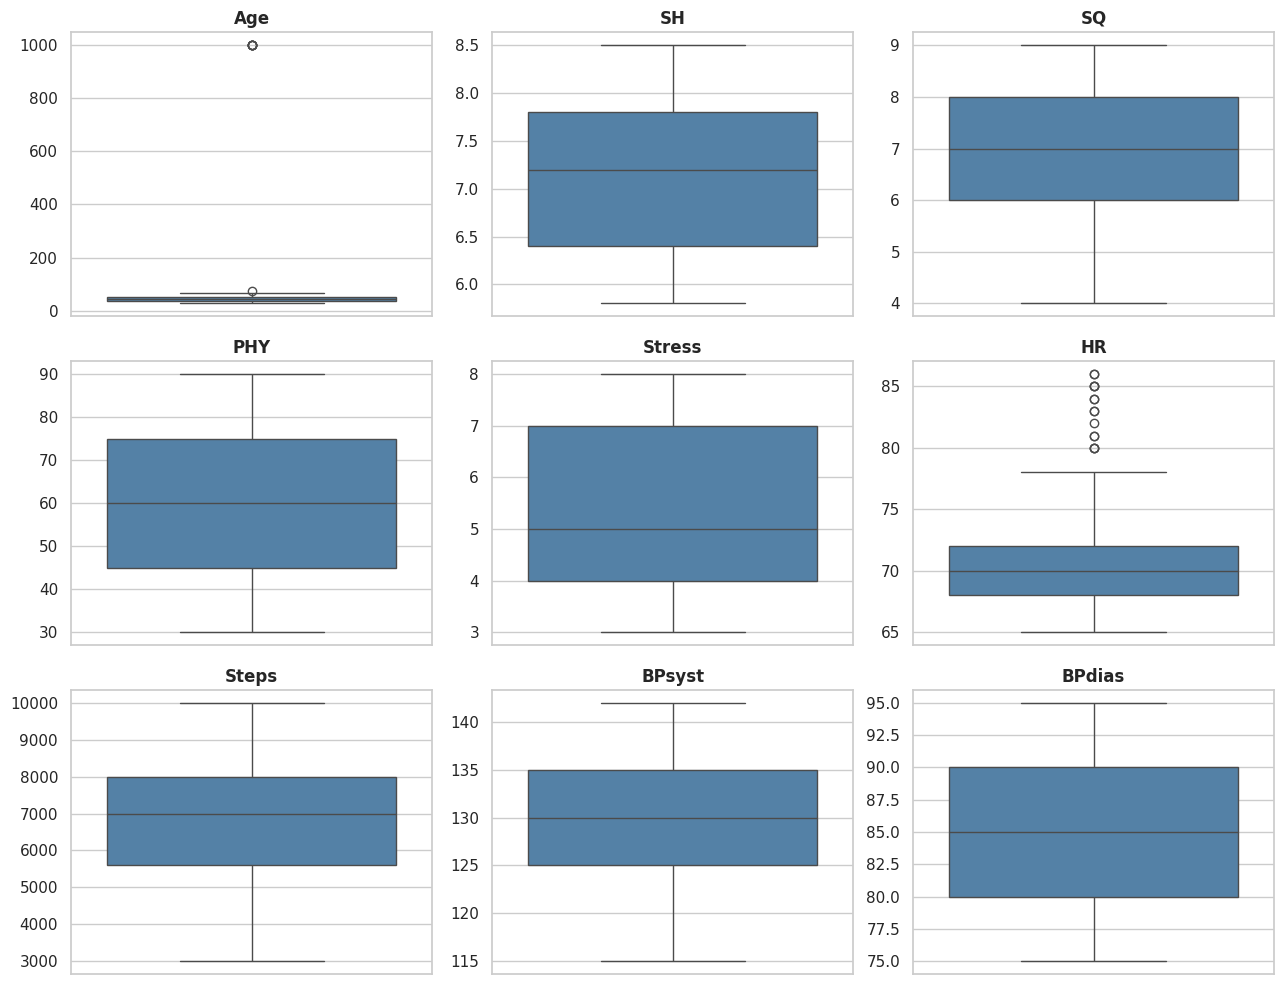

In [16]:
plot_cols = [c for c in num_cols if c != "ID"] + ["BPsyst", "BPdias"]

fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, col in zip(axes.flat, plot_cols):
    sns.boxplot(y=df[col], ax=ax, color="steelblue")
    ax.set_title(col, fontweight="bold")
    ax.set_ylabel("")
for ax in axes.flat[len(plot_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Se observa un valor atípico extremo en **`Age`**, muy por encima del resto de
edades — un claro candidato a **valor centinela** (un código usado para
representar "desconocido", en vez de un dato real). `HR` muestra algunos
valores altos, pero una frecuencia cardíaca en reposo algo por encima de 85
está dentro de la variabilidad fisiológica normal, así que no la tratamos como
error. El resto de variables numéricas no muestra outliers destacables.

### 4.2.1. Manejo de valores atípicos

Para `Age`, identificamos los valores atípicos aplicando la regla del rango
intercuartílico (1.5 × RIC):

In [17]:
Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

outliers_age = df[(df["Age"] < lower) | (df["Age"] > upper)]
outliers_age[["ID", "Age"]]

,ID,Age
41,42,999.0
51,52,999.0
75,76,999.0
130,131,73.0
179,180,999.0
304,305,999.0
333,334,999.0


Todos corresponden al valor centinela `999` ("edad desconocida"). Lo
sustituimos por `NaN`, el estándar para datos faltantes, de forma que se trate
correctamente en los análisis estadísticos y se pueda imputar en el siguiente
apartado.

In [18]:
df["Age"] = df["Age"].replace(999, np.nan)

print("Valores == 999 restantes:", (df["Age"] == 999).sum())
print("Valores NaN en 'Age':", df["Age"].isna().sum())

Valores == 999 restantes: 0
Valores NaN en 'Age': 9


## 5. Imputación

Imputamos los `NaN` de las variables numéricas (excluyendo `ID`) mediante el
método de los **k vecinos más cercanos** (k = 3): cada valor ausente se
sustituye por el promedio del mismo valor en los k registros más parecidos.

In [19]:
impute_cols = [c for c in num_cols if c != "ID"] + ["BPsyst", "BPdias"]

imputer = KNNImputer(n_neighbors=3)
before_na = df[impute_cols].isna()

df_imputed = df.copy()
df_imputed[impute_cols] = imputer.fit_transform(df[impute_cols])

filas_imputadas = before_na.any(axis=1)
df_imputed.loc[filas_imputadas, ["ID"] + impute_cols]

,ID,Age,SH,SQ,PHY,Stress,HR,Steps,BPsyst,BPdias
41,42,31.000000,7.7,7.0,75.0,6.0,70.0,8000.0,120.0,80.0
51,52,34.666667,7.5,8.0,45.0,3.0,70.0,8000.0,120.0,80.0
75,76,32.000000,6.0,6.0,30.0,8.0,72.0,5000.0,125.0,80.0
86,87,35.000000,7.2,8.0,60.0,4.0,65.0,5000.0,125.0,80.0
153,154,39.000000,7.2,8.0,60.0,5.0,68.0,8000.0,130.0,85.0
179,180,43.000000,7.8,8.0,90.0,5.0,70.0,8000.0,130.0,85.0
244,245,44.000000,6.3,6.0,45.0,7.0,72.0,6000.0,130.0,85.0
304,305,49.333333,6.1,6.0,90.0,8.0,75.0,10000.0,140.0,95.0
333,334,52.000000,8.4,9.0,30.0,3.0,65.0,5000.0,125.0,80.0


La tabla anterior muestra los registros donde `Age` ha sido imputado (9 en
total: 3 valores nulos originales más 6 que eran el centinela `999`), usando
el método KNN con $k=3$.

## 6. Correlaciones

### 6.1. Matriz de correlaciones

Calculamos la correlación de Pearson entre todas las variables numéricas y la
visualizamos como un mapa de calor.

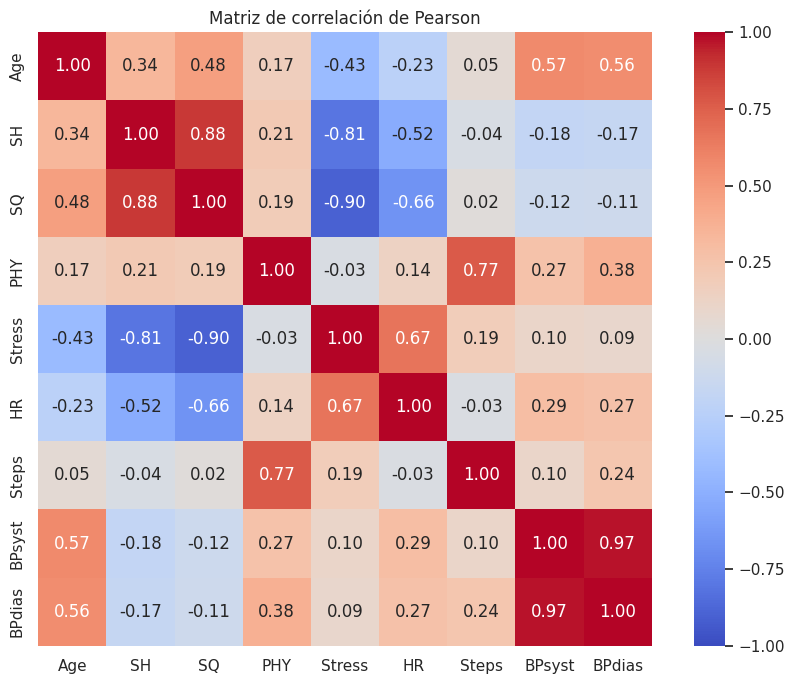

In [20]:
corr_cols = ["Age", "SH", "SQ", "PHY", "Stress", "HR", "Steps", "BPsyst", "BPdias"]
corr_matrix = df_imputed[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Matriz de correlación de Pearson")
plt.tight_layout()
plt.show()

**Interpretación de las correlaciones más relevantes:**

Positivas:

- `BPsyst` y `BPdias` (≈0.97): presión sistólica y diastólica están, como es
  fisiológicamente esperable, fuertemente ligadas.
- `PHY` y `Steps` (≈0.77): más actividad física reportada se traduce en más
  pasos diarios.
- `Stress` y `HR` (≈0.67): a mayor estrés, mayor frecuencia cardíaca.
- `Age` con `BPsyst`/`BPdias` (≈0.56–0.57): la presión arterial tiende a subir
  con la edad.

Negativas:

- `Stress` y `SQ` (≈-0.90) / `Stress` y `SH` (≈-0.81): más estrés se asocia
  con peor calidad y menor duración del sueño — la relación más fuerte de
  todo el dataset.
- `HR` y `SQ` (≈-0.66): una frecuencia cardíaca en reposo más alta se asocia
  con peor calidad de sueño percibida.

### 6.2. Cálculo manual de la correlación de Pearson

Implementamos la fórmula de Pearson sin usar funciones ya existentes para el
cálculo, y validamos el resultado comparándolo con `scipy.stats.pearsonr` y
con `DataFrame.corr()`.

In [21]:
def pearson_manual(x: np.ndarray, y: np.ndarray) -> float:
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if x.shape != y.shape:
        raise ValueError("x e y deben tener la misma longitud")

    mask = ~(np.isnan(x) | np.isnan(y))
    x, y = x[mask], y[mask]

    mean_x, mean_y = x.mean(), y.mean()
    num = np.sum((x - mean_x) * (y - mean_y))
    den = np.sqrt(np.sum((x - mean_x) ** 2) * np.sum((y - mean_y) ** 2))
    return num / den


x = df_imputed["BPsyst"].values
y = df_imputed["BPdias"].values

r_manual = pearson_manual(x, y)
r_scipy, _ = pearsonr(x, y)
r_pandas = df_imputed["BPsyst"].corr(df_imputed["BPdias"])

print(f"Correlación manual:   {r_manual:.6f}")
print(f"Correlación (scipy):  {r_scipy:.6f}")
print(f"Correlación (pandas): {r_pandas:.6f}")

Correlación manual:   0.972885
Correlación (scipy):  0.972885
Correlación (pandas): 0.972885


Los tres valores coinciden, lo que confirma que la implementación manual de
Pearson es correcta.

## 7. Análisis descriptivo y visual

### 7.1. Tabla resumen de tendencia central y variabilidad según `SD`

Media y desviación estándar de `SH`, `SQ`, `HR` y `Stress`, agregadas por tipo
de trastorno del sueño (`SD`).

In [22]:
summary_table = desc.summarize_by_group(
    df_imputed,
    levels=["SD"],
    metric_cols=["SH", "SQ", "HR", "Stress"],
    metrics=["mean", "std"],
)
summary_table.round(2)

,SD,SH_mean,SH_std,SQ_mean,SQ_std,HR_mean,HR_std,Stress_mean,Stress_std
0,Insomnia,6.59,0.39,6.53,0.80,70.47,4.95,5.87,1.46
1,None,7.36,0.73,7.63,0.98,69.02,2.66,5.11,1.59
2,Sleep Apnea,7.03,0.97,7.21,1.65,73.09,5.12,5.67,2.33


### 7.2. Gráfico de medias de `HR` según `Occupation` y `SD`

Un gráfico de líneas con el tipo de `SD` en el eje X y una línea por ocupación,
mostrando la media de `HR` en cada combinación.

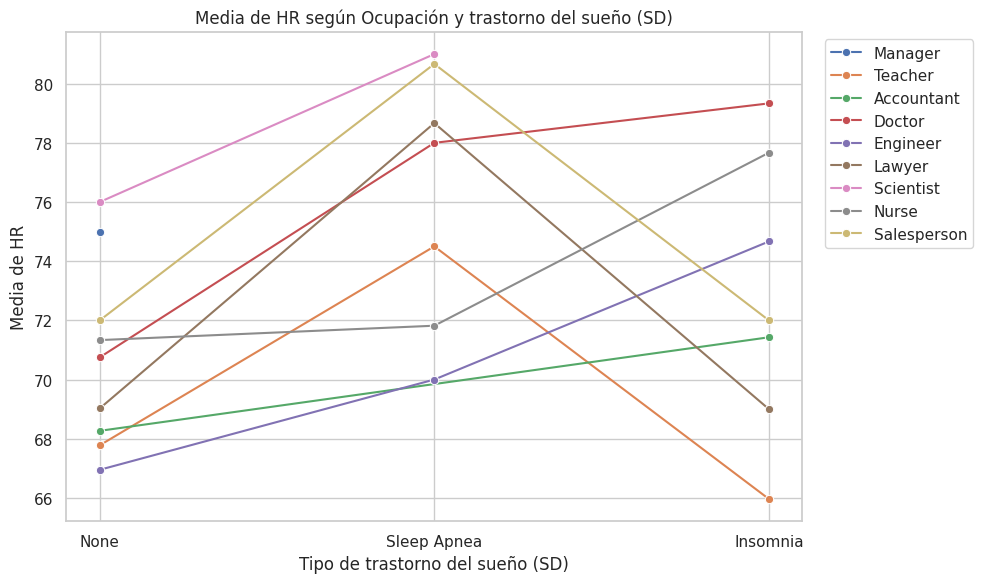

In [23]:
hr_summary = (
    df_imputed.groupby(["SD", "Occupation"])["HR"]
    .mean()
    .reset_index()
)

sd_order = ["None", "Sleep Apnea", "Insomnia"]
hr_summary["SD"] = pd.Categorical(hr_summary["SD"], categories=sd_order, ordered=True)
hr_summary = hr_summary.sort_values("SD")

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=hr_summary, x="SD", y="HR", hue="Occupation",
             marker="o", ax=ax)
ax.set_title("Media de HR según Ocupación y trastorno del sueño (SD)")
ax.set_xlabel("Tipo de trastorno del sueño (SD)")
ax.set_ylabel("Media de HR")
ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 8. Archivo final

Guardamos el resultado del preprocesamiento en un archivo CSV.

In [ ]:
output_path = "output/sleephealth_processed.csv"
df_imputed.to_csv(output_path, index=False)

print(f"Archivo guardado en: {output_path}")
df_imputed.head()

Archivo guardado en: sleephealth_processed.csv


,ID,Gender,Age,Occupation,SH,SQ,PHY,Stress,BMI,BP,HR,Steps,SD,BPsyst,BPdias
0,1,Male,27.0,Engineer,6.1,6.0,42.0,6.0,Overweight,126/83,77.0,4200.0,None,126.0,83.0
1,2,Male,28.0,Doctor,6.2,6.0,60.0,8.0,Normal,125/80,75.0,10000.0,None,125.0,80.0
2,3,Male,28.0,Doctor,6.2,6.0,60.0,8.0,Normal,125/80,75.0,10000.0,None,125.0,80.0
3,4,Male,28.0,Salesperson,5.9,4.0,30.0,8.0,Obese,140/90,85.0,3000.0,Sleep Apnea,140.0,90.0
4,5,Male,28.0,Salesperson,5.9,4.0,30.0,8.0,Obese,140/90,85.0,3000.0,Sleep Apnea,140.0,90.0
